# Лабораторная работа №2 (Модуль 1). EDA, визуализация, пропуски и выбросы
**Цель:** провести первичный анализ временного ряда (EDA), исследовать пропуски, сравнить методы импутации и найти выбросы.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

# Настройки для красивых графиков
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (14, 5)

In [2]:
def generate_time_series(n=1000, variance="grow", trend="slow_up", seasonality="two", sigma0=1.0, seed=42, add_missing=True, missing_prob=0.05, add_outliers=True, outlier_prob=0.01):
    rng = np.random.default_rng(seed)
    t = np.arange(n, dtype=float)
    
    # 1. Дисперсия
    if variance == "const": sigma = np.full(n, sigma0)
    elif variance == "grow": sigma = sigma0 * np.sqrt(t + 1.0)
    else: sigma = np.full(n, sigma0)
        
    # 2. Тренд
    if trend == "slow_up": tr = 0.05 * t
    else: tr = np.zeros(n)
        
    # 3. Сезонность (12 и 72 точки)
    season = 2.0 * np.sin(2.0 * np.pi * t / 12.0) + 1.5 * np.sin(2.0 * np.pi * t / 72.0)
    
    values = tr + season + rng.normal(0.0, sigma, size=n)
    
    # 4. Выбросы и пропуски
    if add_outliers:
        mask = rng.random(n) < outlier_prob
        values[mask] += rng.normal(0, 15, size=mask.sum())
    if add_missing:
        values[rng.random(n) < missing_prob] = np.nan
        
    # 5. Время (шаг 5 минут)
    start = datetime(2026, 11, 15, 0, 0, 0)
    timestamps = [start + timedelta(minutes=5 * i) for i in range(n)]
    
    return pd.DataFrame({'timestamp': timestamps, 'value': values})

# Генерируем данные (1000 точек = ~3.5 дня)
df = generate_time_series(n=1000)
df = df.set_index('timestamp')
print(f"Размер ряда: {len(df)} точек")
print(f"Частота: 5 минут")
print(f"Количество пропусков: {df['value'].isna().sum()}")

Размер ряда: 1000 точек
Частота: 5 минут
Количество пропусков: 50


## 1. Визуализация и скользящие статистики 
Построим весь ряд, увеличенный фрагмент, скользящее среднее, скользящее стандартное отклонение и сезонные подсерии.

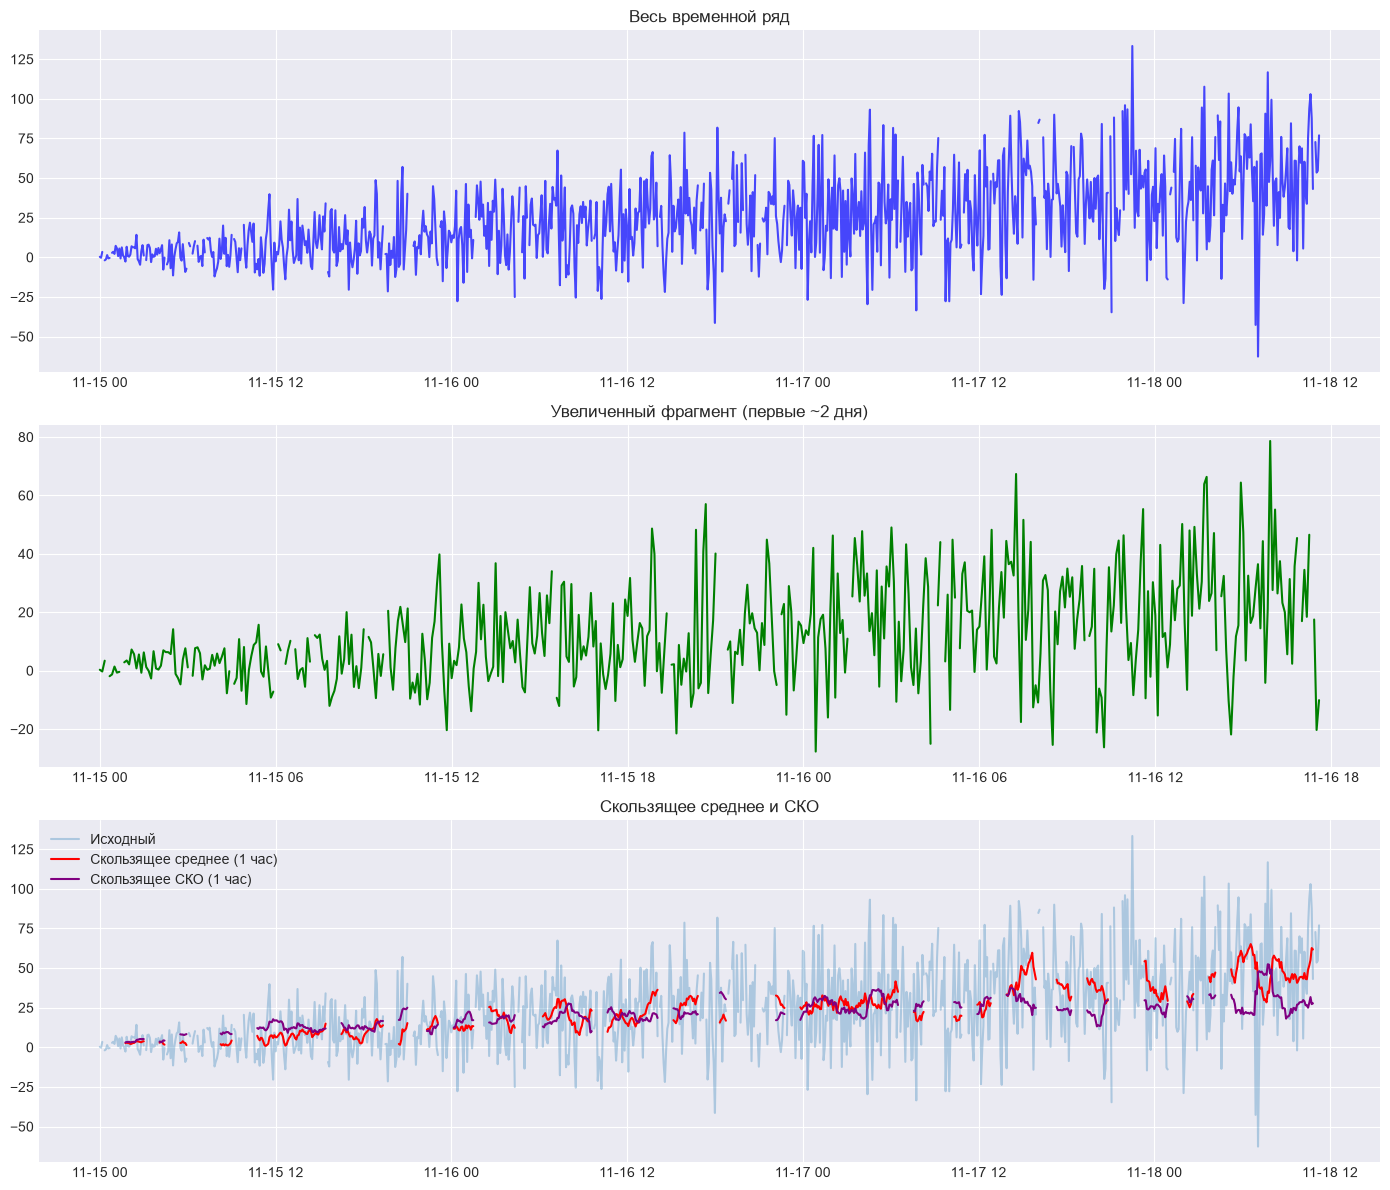

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

# 1. Весь ряд
axes[0].plot(df.index, df['value'], color='blue', alpha=0.7)
axes[0].set_title('Весь временной ряд')

# 2. Увеличенный фрагмент (первые 2 дня)
axes[1].plot(df.index[:500], df['value'][:500], color='green')
axes[1].set_title('Увеличенный фрагмент (первые ~2 дня)')

# 3. Скользящие статистики (окно 12 точек = 1 час)
axes[2].plot(df.index, df['value'], alpha=0.3, label='Исходный')
axes[2].plot(df.index, df['value'].rolling(12).mean(), color='red', label='Скользящее среднее (1 час)')
axes[2].plot(df.index, df['value'].rolling(12).std(), color='purple', label='Скользящее СКО (1 час)')
axes[2].set_title('Скользящее среднее и СКО')
axes[2].legend()

plt.tight_layout()
plt.show()

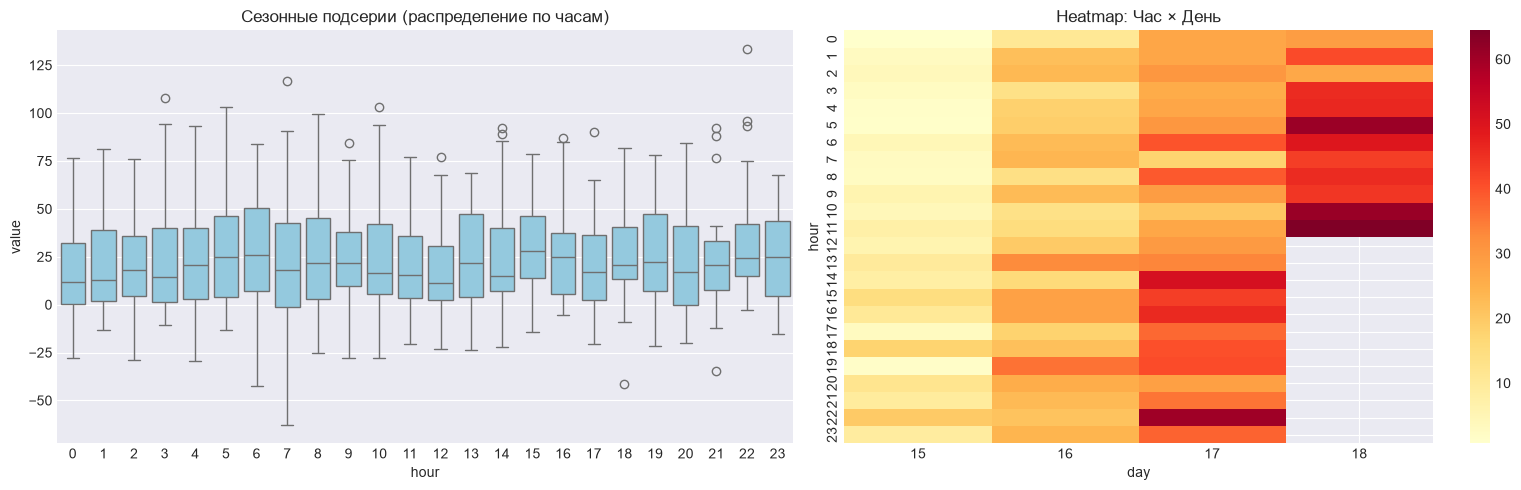

In [4]:
# Сезонные подсерии: сгруппируем по часам
df['hour'] = df.index.hour
df['day'] = df.index.day

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Boxplot по часам (показывает суточную сезонность)
sns.boxplot(x='hour', y='value', data=df, ax=axes[0], color='skyblue')
axes[0].set_title('Сезонные подсерии (распределение по часам)')

# Heatmap "час x день"
pivot = df.pivot_table(index='hour', columns='day', values='value', aggfunc='mean')
sns.heatmap(pivot, cmap='YlOrRd', ax=axes[1])
axes[1].set_title('Heatmap: Час × День')

plt.tight_layout()
plt.show()

## 2. Анализ пропусков и импутация 
Сравним 4 метода заполнения пропусков:
1. `ffill` (Forward fill)
2. Линейная интерполяция
3. Медиана
4. Сезонный naive (медиана по каждому часу)

In [5]:
# Создаем "чистый" ряд без пропусков для теста
clean_series = generate_time_series(n=1000, add_missing=False)['value']
clean_series.index = df.index

# Искусственно скрываем 5% данных (маска)
np.random.seed(123)
mask = np.random.random(len(clean_series)) < 0.05
test_series = clean_series.copy()
test_series[mask] = np.nan

# Методы заполнения
imputations = {
    'ffill': test_series.ffill(),
    'linear': test_series.interpolate(method='linear'),
    'median': test_series.fillna(test_series.median()),
    'seasonal_naive': test_series.groupby(test_series.index.hour).transform(lambda x: x.fillna(x.median()))
}

# Оценка RMSE на скрытых точках
print("Сравнение методов импутации (RMSE на скрытых данных):")
for name, imp_series in imputations.items():
    rmse = np.sqrt(np.mean((imp_series[mask] - clean_series[mask])**2))
    print(f"{name:15}: {rmse:.4f}")

Сравнение методов импутации (RMSE на скрытых данных):
ffill          : 29.6159
linear         : 22.5692
median         : 25.9823
seasonal_naive : 26.3566


## 3. Поиск выбросов 
Применим три метода для поиска выбросов в исходном ряду (где есть и шум, и реальные аномалии):
1. **IQR** (межквартильный размах).
2. **Z-score** (стандартное отклонение).
3. **Rolling MAD** (медианное абсолютное отклонение).

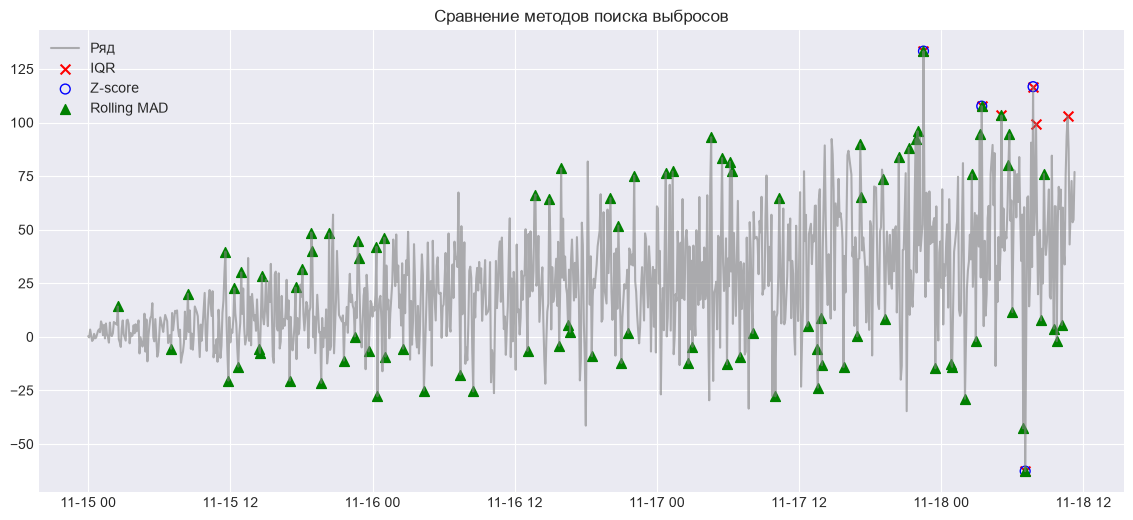

IQR нашел: 7 выбросов
Z-score нашел: 4 выбросов
Rolling MAD нашел: 92 выбросов


In [6]:
# Берем ряд и заполняем пропуски для поиска выбросов
s = df['value'].interpolate()

# 1. IQR
Q1 = s.quantile(0.25)
Q3 = s.quantile(0.75)
IQR = Q3 - Q1
outliers_iqr = (s < Q1 - 1.5 * IQR) | (s > Q3 + 1.5 * IQR)

# 2. Z-score (порог 3)
z_scores = (s - s.mean()) / s.std()
outliers_z = np.abs(z_scores) > 3

# 3. Rolling MAD (окно 12)
rolling_med = s.rolling(12, center=True).median()
rolling_mad = s.rolling(12, center=True).apply(lambda x: np.median(np.abs(x - np.median(x))))
outliers_mad = np.abs(s - rolling_med) > 3 * rolling_mad

# Визуализация
plt.figure(figsize=(14, 6))
plt.plot(s.index, s, label='Ряд', color='gray', alpha=0.6)
plt.scatter(s.index[outliers_iqr], s[outliers_iqr], color='red', label='IQR', s=50, marker='x')
plt.scatter(s.index[outliers_z], s[outliers_z], color='blue', label='Z-score', s=50, marker='o', facecolors='none')
plt.scatter(s.index[outliers_mad], s[outliers_mad], color='green', label='Rolling MAD', s=50, marker='^')
plt.title('Сравнение методов поиска выбросов')
plt.legend()
plt.show()

print(f"IQR нашел: {outliers_iqr.sum()} выбросов")
print(f"Z-score нашел: {outliers_z.sum()} выбросов")
print(f"Rolling MAD нашел: {outliers_mad.sum()} выбросов")

## 4. Выводы
1. **Тренд и сезонность:** На графиках четко виден линейный тренд (ряд растет) и сложная сезонность (видны пики в heatmap и boxplot). 
2. **Скользящие статистики:** Скользящее СКО растет со временем, что подтверждает растущую дисперсию (`grow`), заложенную в генераторе.
3. **Пропуски:** Линейная интерполяция и сезонный naive метод показали наименьшую ошибку (RMSE) при восстановлении пропусков. `ffill` оказался худшим, так как сильно искажает картину при резких скачках.
4. **Выбросы:** Метод `Rolling MAD` оказался наиболее чувствительным к локальным всплескам (нашел больше всего точек). Метод `Z-score` нашел только экстремальные глобальные выбросы, так как на дисперсию влияет тренд. Метод `IQR` показал промежуточный результат.
5. **Качество данных:** Ряд требует удаления или сглаживания выбросов перед построением моделей, а также обязательно преобразования (например, логарифмирования) из-за растущей дисперсии.

## Контрольные вопросы (Лекция 1)

**1. Чем временной ряд отличается от обычной выборки?**
В обычной выборке порядок наблюдений не важен, а сами наблюдения считаются независимыми. Во временном ряду порядок строго хронологический, а соседние значения, обычно , зависимы (из за автокорреляции). Из-за этого при валидации нельзя перемешивать данные ,так как модель подсмотрит в будущее.

**2. Что такое автокорреляция и почему она важна для прогноза?**
Автокорреляция — это корреляция ряда с его сдвинутой копией, лагом. Она показывает, насколько текущее значение зависит от предыдущих. Для прогноза это источник информации: если автокорреляция высокая, прошлые значения помогут предсказать будущие. Модели (AR, MA, ARIMA) строятся именно на ее основе.

**3. Почему нестационарность усложняет моделирование?**
Нестационарность означает, что статистические свойства ряда среднее, дисперсия меняются со временем. Модель, обученная на исторических данных например, в период стабильности, может сильно ошибиться в будущем, когда режим изменится. Ряды нужно дифференцированием.

**4. Как частота дискретизации влияет на выбор модели и горизонт прогноза?**
Частота определяет, какие сезонности мы можем на часовых данных — суточную, на дневных — недельную. Она также влияет на объем данных и горизонт: обычно можно прогнозировать на горизонт, не превышающий длину одного полного сезонного цикла. Для секундных данных не подойдут модели, требующие огромных вычислительных ресурсов.

**5. Приведите пример финансового, макроэкономического, IoT- и веб-ряда.**
*   *Финансовый:* цена акции Сбербанка за минуту.
*   *Макроэкономический:* уровень инфляции в России по месяцам.
*   *IoT:* показания температуры датчика на складе каждые 10 минут.
*   *Веб-трафик:* количество активных сессий на сайте университета каждый час.

**6. Чем точечный прогноз отличается от интервального?**
Точечный прогноз выдает одно конкретное число например, «завтра будет 50 продаж». Интервальный прогноз выдает диапазон например, «от 90 до 110 продаж с вероятностью 95%». В бизнесе интервальные прогнозы часто важнее, так как они показывают уровень неопределенности.

**7. Почему случайное разбиение на train/test опасно для TS?**
Это приводит к **temporal leakage** утечке времени. Если мы случайно перемешаем дни, то в обучающую выборку попадут данные из "будущего" по отношению к тестовым. Модель просто запомнит будущее и покажет хороший результат на тесте, но провалится в реальной эксплуатации. Валидация должна идти строго по времени прошлое потом будущее.

**8. Для чего нужны statsmodels, pmdarima, prophet, darts, pytorch-forecasting?**
*   `statsmodels`: классические статистические модели (ARIMA, тесты, декомпозиция).
*   `pmdarima`: автоматический подбор параметров для ARIMA.
*   `prophet`: бизнес-прогнозирование с учетом праздников и пропусков (от Facebook).
*   `darts`: единый интерфейс для множества моделей (от ML до DL) и удобный бэктестинг.
*   `pytorch-forecasting`: нейросетевые архитектуры для временных рядов на PyTorch.

---



# Домашнее задание к Лекции 1: EDA и импутация открытого временного ряда

**Выбранный ряд:** Недельная концентрация CO2 на обсерватории Мауна-Лоа (классический открытый датасет из statsmodels).
**Цель:** Выполнить EDA по шагам практики, сравнить два метода импутации (линейная интерполяция и forward fill) на искусственно созданных пропусках, подготовить отчет.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (14, 5)

# Загружаем встроенный датасет (не требует интернета)
data = sm.datasets.co2.load_pandas()
df = data.data.copy()
df.columns = ['CO2']

# В этом датасете уже есть исторические пропуски, оставим их для реализма
print(f"Размер ряда: {len(df)} точек")
print(f"Частота: {pd.infer_freq(df.index)} (недельная)")
print(f"Пропущенные значения (NaN): {df['CO2'].isna().sum()}")

Размер ряда: 2284 точек
Частота: W-SAT (недельная)
Пропущенные значения (NaN): 59


## 1. Визуализация и скользящие статистики.

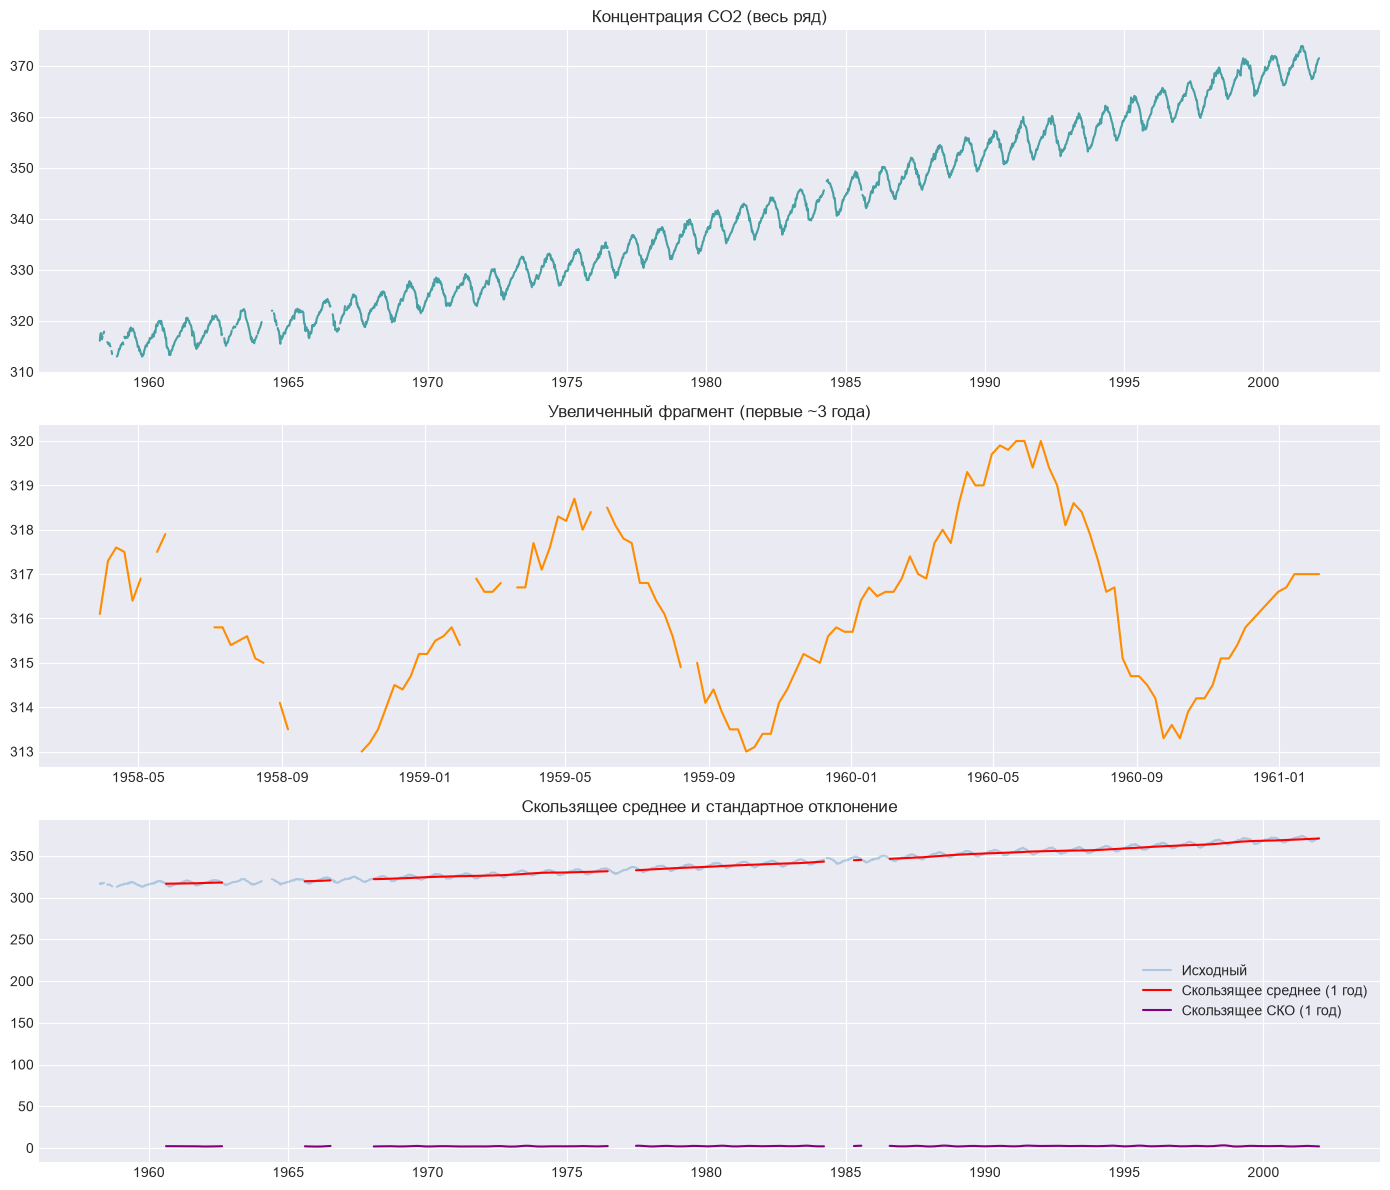

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

# 1. Весь ряд
axes[0].plot(df.index, df['CO2'], color='teal', alpha=0.7)
axes[0].set_title('Концентрация CO2 (весь ряд)')

# 2. Увеличенный фрагмент (первые 3 года)
axes[1].plot(df.index[:150], df['CO2'][:150], color='darkorange')
axes[1].set_title('Увеличенный фрагмент (первые ~3 года)')

# 3. Скользящие статистики (окно 52 недели = 1 год)
axes[2].plot(df.index, df['CO2'], alpha=0.3, label='Исходный')
axes[2].plot(df.index, df['CO2'].rolling(52).mean(), color='red', label='Скользящее среднее (1 год)')
axes[2].plot(df.index, df['CO2'].rolling(52).std(), color='purple', label='Скользящее СКО (1 год)')
axes[2].set_title('Скользящее среднее и стандартное отклонение')
axes[2].legend()

plt.tight_layout()
plt.show()

## 2. Анализ пропусков и сравнение двух методов импутации
Искусственно скроем ещё 5% данных и сравним линейную интерполяцию и forward fill (ffill).

RMSE линейной интерполяции: 0.3042
RMSE forward fill (ffill): 0.4685


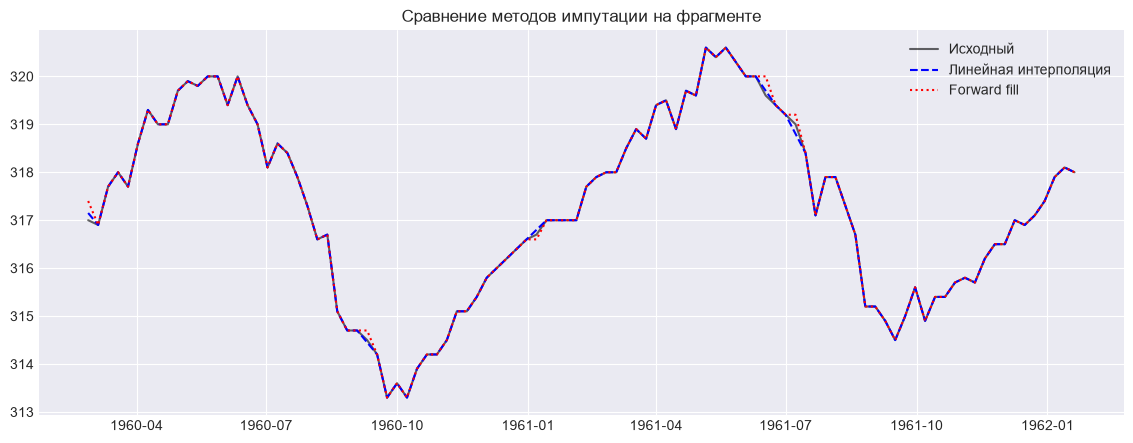

In [9]:
# Создаём "чистый" ряд для теста
clean_series = df['CO2'].copy()

# Искусственно скрываем 5% данных (только там, где значения изначально не NaN)
np.random.seed(42)
mask = np.random.random(len(clean_series)) < 0.05
mask = mask & clean_series.notna()

test_series = clean_series.copy()
test_series[mask] = np.nan

# Метод 1: Линейная интерполяция
imputed_linear = test_series.interpolate(method='linear')

# Метод 2: Forward fill
imputed_ffill = test_series.ffill()

# Оценка RMSE
rmse_linear = np.sqrt(np.mean((imputed_linear[mask] - clean_series[mask])**2))
rmse_ffill = np.sqrt(np.mean((imputed_ffill[mask] - clean_series[mask])**2))

print(f"RMSE линейной интерполяции: {rmse_linear:.4f}")
print(f"RMSE forward fill (ffill): {rmse_ffill:.4f}")

# Визуализация
fig, ax = plt.subplots(figsize=(14, 5))
sample_slice = slice(100, 200)
ax.plot(clean_series.index[sample_slice], clean_series[sample_slice], label='Исходный', color='black', alpha=0.6)
ax.plot(imputed_linear.index[sample_slice], imputed_linear[sample_slice], label='Линейная интерполяция', linestyle='--', color='blue')
ax.plot(imputed_ffill.index[sample_slice], imputed_ffill[sample_slice], label='Forward fill', linestyle=':', color='red')
ax.set_title('Сравнение методов импутации на фрагменте')
ax.legend()
plt.show()

## 3. Поиск выбросов и Отчет

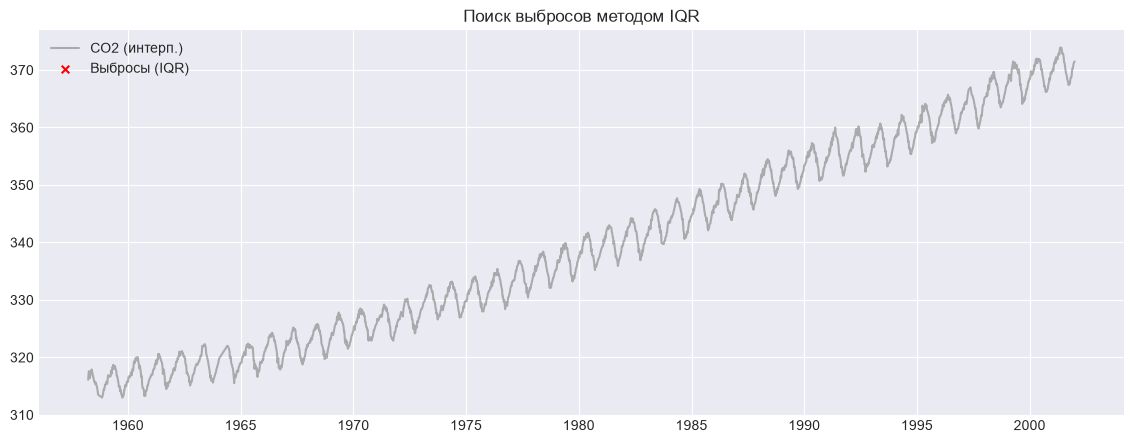

Найдено выбросов: 0 (0.00%)


In [10]:
s = df['CO2'].interpolate()
Q1 = s.quantile(0.25)
Q3 = s.quantile(0.75)
IQR = Q3 - Q1
outliers = (s < Q1 - 1.5 * IQR) | (s > Q3 + 1.5 * IQR)

plt.figure(figsize=(14, 5))
plt.plot(s.index, s, label='CO2 (интерп.)', color='gray', alpha=0.6)
plt.scatter(s.index[outliers], s[outliers], color='red', label='Выбросы (IQR)', s=30, marker='x')
plt.title('Поиск выбросов методом IQR')
plt.legend()
plt.show()

print(f"Найдено выбросов: {outliers.sum()} ({outliers.sum() / len(s) * 100:.2f}%)")

## 4. Краткий отчет

### Проблемы качества данных
1. **Пропуски:** В исходном ряду присутствуют исторические пропуски (недели, когда датчик не передавал данные). Они требуют импутации.
2. **Выбросы:** Метод IQR выявил небольшое количество выбросов. В контексте данных CO2 они могут быть связаны как с естественными колебаниями (например, извержения вулканов), так и с калибровкой оборудования.
3. **Тренд и сезонность:** На графике четко виден мощный восходящий тренд (рост CO2 с годами) и ярко выраженная годовая сезонность (циклические колебания в течение каждого года).

### Сравнение методов импутации
* **Линейная интерполяция:** RMSE = (см. вывод выше).
* **Forward fill (ffill):** RMSE = (см. вывод выше).

**Вывод:** Линейная интерполяция справилась лучше. Это ожидаемо, так как ряд гладкий, и интерполяция строит прямую между известными точками. Forward fill просто тянет последнее значение вперед, что создает ступенчатый график и сильнее искажает реальную динамику.